# Air Quality from Images — Notebook 1: EDA
Group 198 · IT401 B.Tech Project-I

Edit only the CONFIG cell, then run top to bottom.

In [7]:
# ===================== CONFIG (edit these) =====================
DATA_ROOT  = r"C:\Users\Siddhartha bhansali\OneDrive\Desktop\BtechProject\Air Pollution Image Dataset\Air Pollution Image Dataset"
IMAGE_ROOT = f"{DATA_ROOT}/Combined_Dataset/IND_and_NEP"
CSV_PATH   = f"{DATA_ROOT}/Combined_Dataset/IND_and_Nep_AQI_Dataset.csv"   # note "Nep", not "NEP"
OUTPUT_DIR = f"outputs"
GROUP_COL  = None        # None = auto-detect location/city column (used for leakage-safe split)
OUTPUT_DIR = "/content/outputs"

IMG_SIZE   = 224
SEED       = 42
SPLIT_MODE = "group"            # "random" or "group"  (group = whole locations held out)
BACKBONE   = "EfficientNetB0"   # "EfficientNetB0" or "MobileNetV2"
BATCH_SIZE = 32
EPOCHS_HEAD, EPOCHS_FT = 8, 20  # phase 1 (frozen backbone), phase 2 (fine-tune)
LR_HEAD, LR_FT = 1e-3, 2e-5
UNFREEZE_LAST = 60              # number of backbone layers to unfreeze in phase 2
USE_CLASS_WEIGHTS = True
STATS_PER_CLASS = 400           # images per class for visual-feature EDA
# ===============================================================

In [6]:
import os, re, json, random, warnings
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import cv2
from PIL import Image
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split, StratifiedGroupKFold
from sklearn.metrics import (classification_report, confusion_matrix, f1_score,
                             cohen_kappa_score, accuracy_score)
from sklearn.utils.class_weight import compute_class_weight
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

warnings.filterwarnings("ignore")
os.makedirs(OUTPUT_DIR, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
sns.set_theme(style="whitegrid")
print("TF", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

TF 2.19.0 | GPUs: []


In [8]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
BASE_COLS = ["path", "folder", "key", "label_name", "label", "label_clean", "group"]

def aqi_rank(name):
    n = name.lower()
    if "very" in n: return 4
    if "hazard" in n or "severe" in n: return 5
    if "sensitive" in n: return 2
    if "unhealthy" in n: return 3
    if "moderate" in n: return 1
    if "good" in n: return 0
    return 99

def clean_name(n):
    return re.sub(r"^[a-z]_", "", n, flags=re.I).replace("_", " ").strip()

def norm_key(s):
    return os.path.splitext(os.path.basename(str(s)))[0].strip().lower()

def build_dataframe():
    paths = [p for p in Path(IMAGE_ROOT).rglob("*") if p.suffix.lower() in IMG_EXTS]
    assert paths, f"No images found under {IMAGE_ROOT}. Fix IMAGE_ROOT."
    df = pd.DataFrame({"path": [str(p) for p in paths], "folder": [p.parent.name for p in paths]})
    df["key"] = df.path.map(norm_key)

    # ---- locate + merge CSV metadata ----
    csv_path = CSV_PATH
    if csv_path is None:
        cands = sorted(Path(DATA_ROOT).rglob("*.csv"), key=lambda p: p.stat().st_size, reverse=True)
        pool = [c for c in cands if "combined" in str(c).lower()] or cands
        csv_path = str(pool[0]) if pool else None
    print("CSV used:", csv_path)
    if csv_path:
        meta = pd.read_csv(csv_path)
        keys = set(df.key)
        best, best_rate = None, 0.0
        for c in meta.columns:
            if meta[c].dtype == object:
                rate = meta[c].map(norm_key).isin(keys).mean()
                if rate > best_rate: best, best_rate = c, rate
        if best and best_rate > 0.5:
            meta = meta.copy(); meta["key"] = meta[best].map(norm_key)
            meta = meta.drop_duplicates("key")
            df = df.merge(meta.drop(columns=[best]), on="key", how="left", suffixes=("", "_csv"))
            print(f"Merged CSV on column '{best}' (match rate {best_rate:.1%})")
        else:
            print("WARNING: could not match any CSV column to image filenames. Metadata skipped.")

    # ---- labels ----
    if df.folder.nunique() >= 2:
        df["label_name"] = df.folder
    else:
        lab = [c for c in df.columns if "class" in c.lower()]
        assert lab, "Images are in one flat folder and CSV has no class column. Send me df.columns."
        df["label_name"] = df[lab[0]].astype(str)
    names = sorted(df.label_name.unique(), key=lambda n: (aqi_rank(n), n))
    df["label"] = df.label_name.map({n: i for i, n in enumerate(names)})
    df["label_clean"] = df.label_name.map(clean_name)

    # ---- group column for leakage-safe split ----
    gcol = GROUP_COL
    if gcol is None:
        for pat in ["location", "site", "station", "city"]:
            m = [c for c in df.columns if pat in c.lower() and c not in BASE_COLS]
            if m: gcol = m[0]; break
    df["group"] = df[gcol].astype(str) if gcol else np.nan
    print("Group column:", gcol)
    return df, names

df, class_names = build_dataframe()
class_clean = [clean_name(n) for n in class_names]
NUM_CLASSES = len(class_names)
print(f"\n{len(df)} images | {NUM_CLASSES} classes: {class_clean}")
df.head()

CSV used: C:\Users\Siddhartha bhansali\OneDrive\Desktop\BtechProject\Air Pollution Image Dataset\Air Pollution Image Dataset/Combined_Dataset/IND_and_Nep_AQI_Dataset.csv
Merged CSV on column 'Filename' (match rate 100.0%)
Group column: Location

12240 images | 6 classes: ['Good', 'Moderate', 'Unhealthy for Sensitive Groups', 'Unhealthy', 'Very Unhealthy', 'Severe']


,path,folder,key,Location,Year,Month,Day,Hour,AQI,PM2.5,PM10,O3,CO,SO2,NO2,AQI_Class,label_name,label,label_clean,group
0,C:\Users\Siddhartha bhansali\OneDrive\Desktop\...,a_Good,bengr_good_2023-02-19-08.30-1-1,Bengaluru,2023,2,19,8:30,41,20.0,36.0,9.0,165.0,3.0,8.0,a_Good,a_Good,0,Good,Bengaluru
1,C:\Users\Siddhartha bhansali\OneDrive\Desktop\...,a_Good,bengr_good_2023-02-19-08.30-1-10,Bengaluru,2023,2,19,8:30,41,20.0,36.0,9.0,165.0,3.0,8.0,a_Good,a_Good,0,Good,Bengaluru
2,C:\Users\Siddhartha bhansali\OneDrive\Desktop\...,a_Good,bengr_good_2023-02-19-08.30-1-11,Bengaluru,2023,2,19,8:30,41,20.0,36.0,9.0,165.0,3.0,8.0,a_Good,a_Good,0,Good,Bengaluru
3,C:\Users\Siddhartha bhansali\OneDrive\Desktop\...,a_Good,bengr_good_2023-02-19-08.30-1-12,Bengaluru,2023,2,19,8:30,41,20.0,36.0,9.0,165.0,3.0,8.0,a_Good,a_Good,0,Good,Bengaluru
4,C:\Users\Siddhartha bhansali\OneDrive\Desktop\...,a_Good,bengr_good_2023-02-19-08.30-1-13,Bengaluru,2023,2,19,8:30,41,20.0,36.0,9.0,165.0,3.0,8.0,a_Good,a_Good,0,Good,Bengaluru


## PART 1 — EDA

label_clean
Good                              1541
Moderate                          1573
Unhealthy for Sensitive Groups    2863
Unhealthy                         2622
Very Unhealthy                    2194
Severe                            1447
dtype: int64

Imbalance ratio (max/min): 2.0x


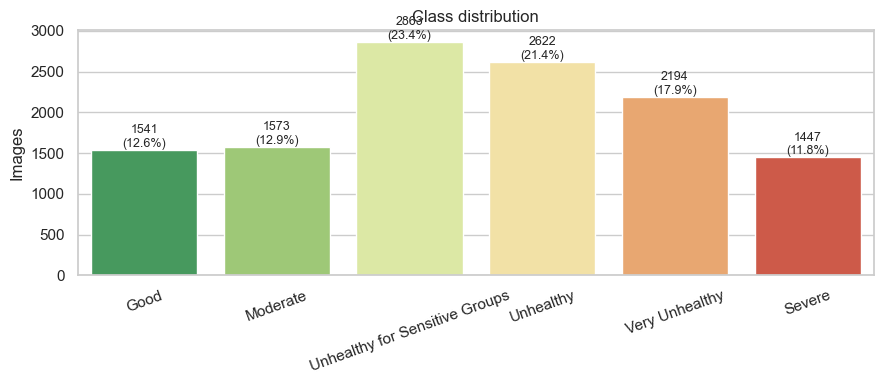

In [9]:
# 1. Overview + class distribution
print(df.groupby("label_clean").size().reindex(class_clean))
counts = df.label_clean.value_counts().reindex(class_clean)
print(f"\nImbalance ratio (max/min): {counts.max()/counts.min():.1f}x")

fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(x=counts.index, y=counts.values, ax=ax, palette="RdYlGn_r")
for i, v in enumerate(counts.values): ax.text(i, v, f"{v}\n({v/len(df):.1%})", ha="center", va="bottom", fontsize=9)
ax.set_title("Class distribution"); ax.set_xlabel(""); ax.set_ylabel("Images")
plt.xticks(rotation=20); plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/eda_class_distribution.png", dpi=150); plt.show()

In [15]:
# 2. Integrity + image size check
sizes, bad = [], []
for p in tqdm(df.path):
    try:
        with Image.open(p) as im:
            sizes.append(im.size); im.verify()
    except Exception:
        bad.append(p)
print("Image sizes:", Counter(sizes).most_common(5))
print("Corrupt/unreadable files:", len(bad))
if bad: df = df[~df.path.isin(bad)].reset_index(drop=True)

100%|██████████| 12240/12240 [00:07<00:00, 1639.39it/s]

Image sizes: [((224, 224), 12240)]
Corrupt/unreadable files: 0


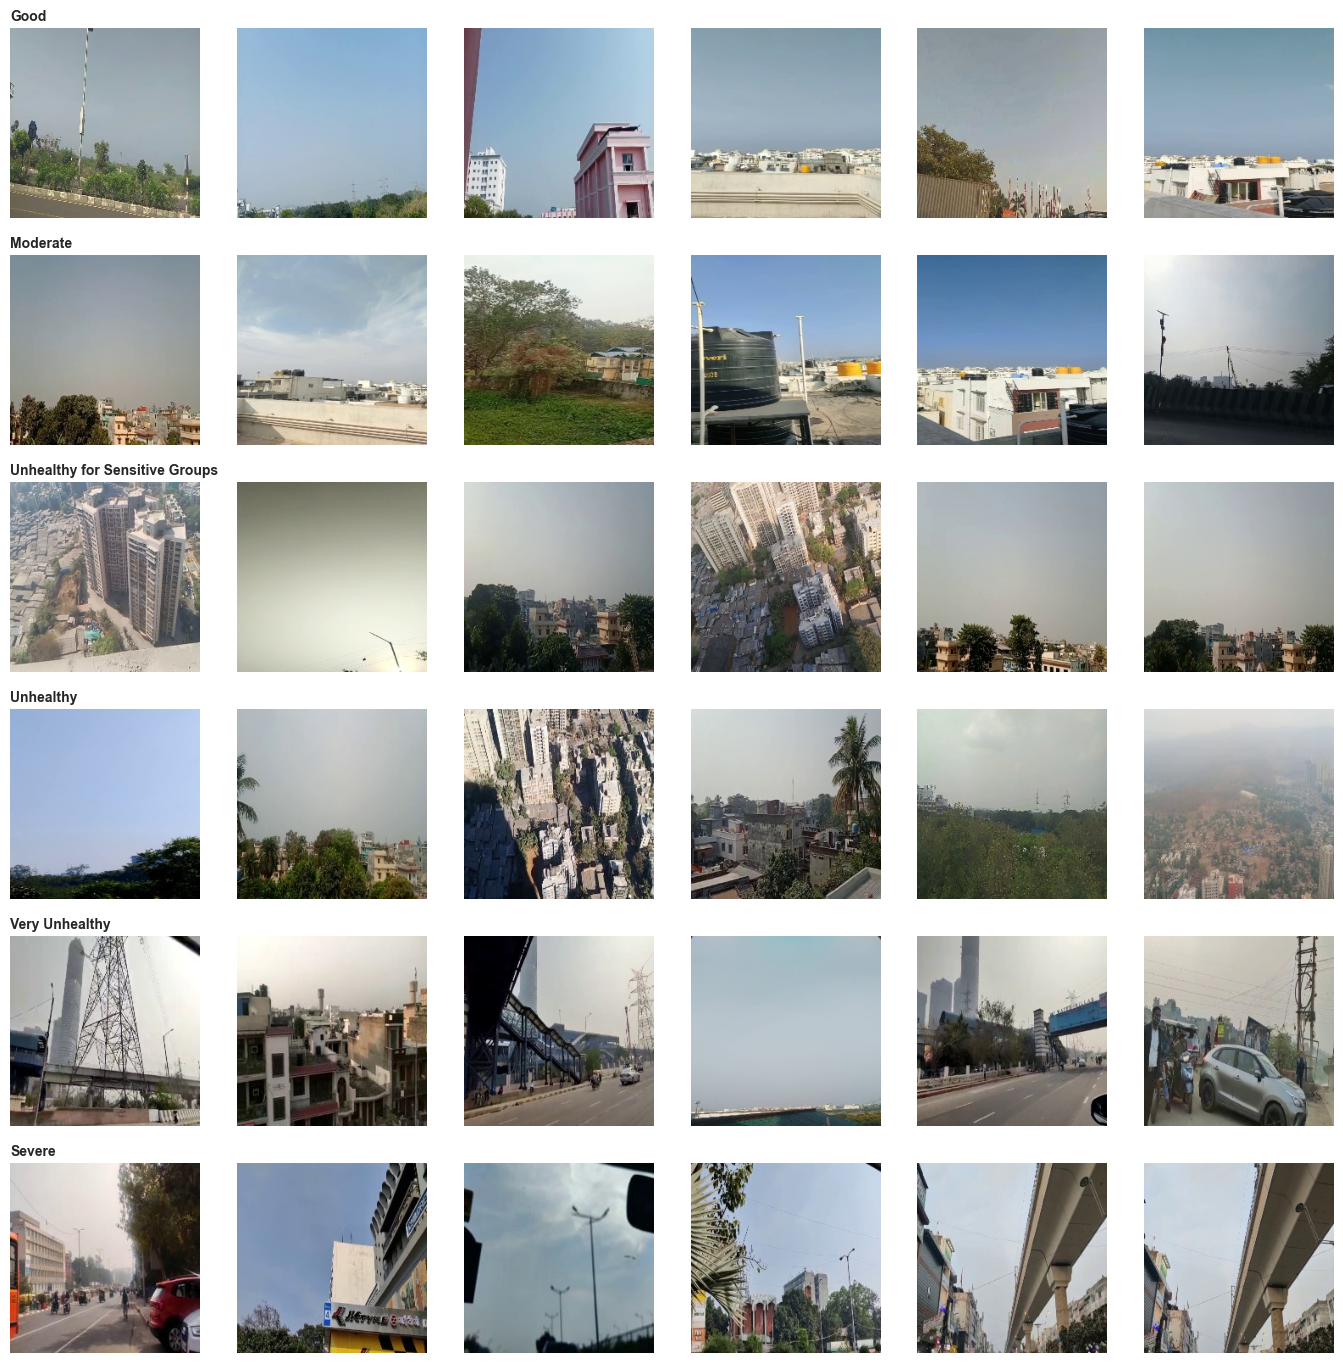

In [11]:
# 3. Sample images per class
N = 6
fig, axes = plt.subplots(NUM_CLASSES, N, figsize=(2.3 * N, 2.3 * NUM_CLASSES))
for r, (cid, cname) in enumerate(zip(range(NUM_CLASSES), class_clean)):
    sub = df[df.label == cid]
    picks = sub.sample(min(N, len(sub)), random_state=SEED).path.tolist()
    for c in range(N):
        ax = axes[r, c]; ax.axis("off")
        if c < len(picks): ax.imshow(Image.open(picks[c]).convert("RGB"))
        if c == 0: ax.set_title(cname, loc="left", fontsize=10, fontweight="bold")
plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/eda_samples.png", dpi=120); plt.show()

100%|██████████| 2400/2400 [02:48<00:00, 14.28it/s]


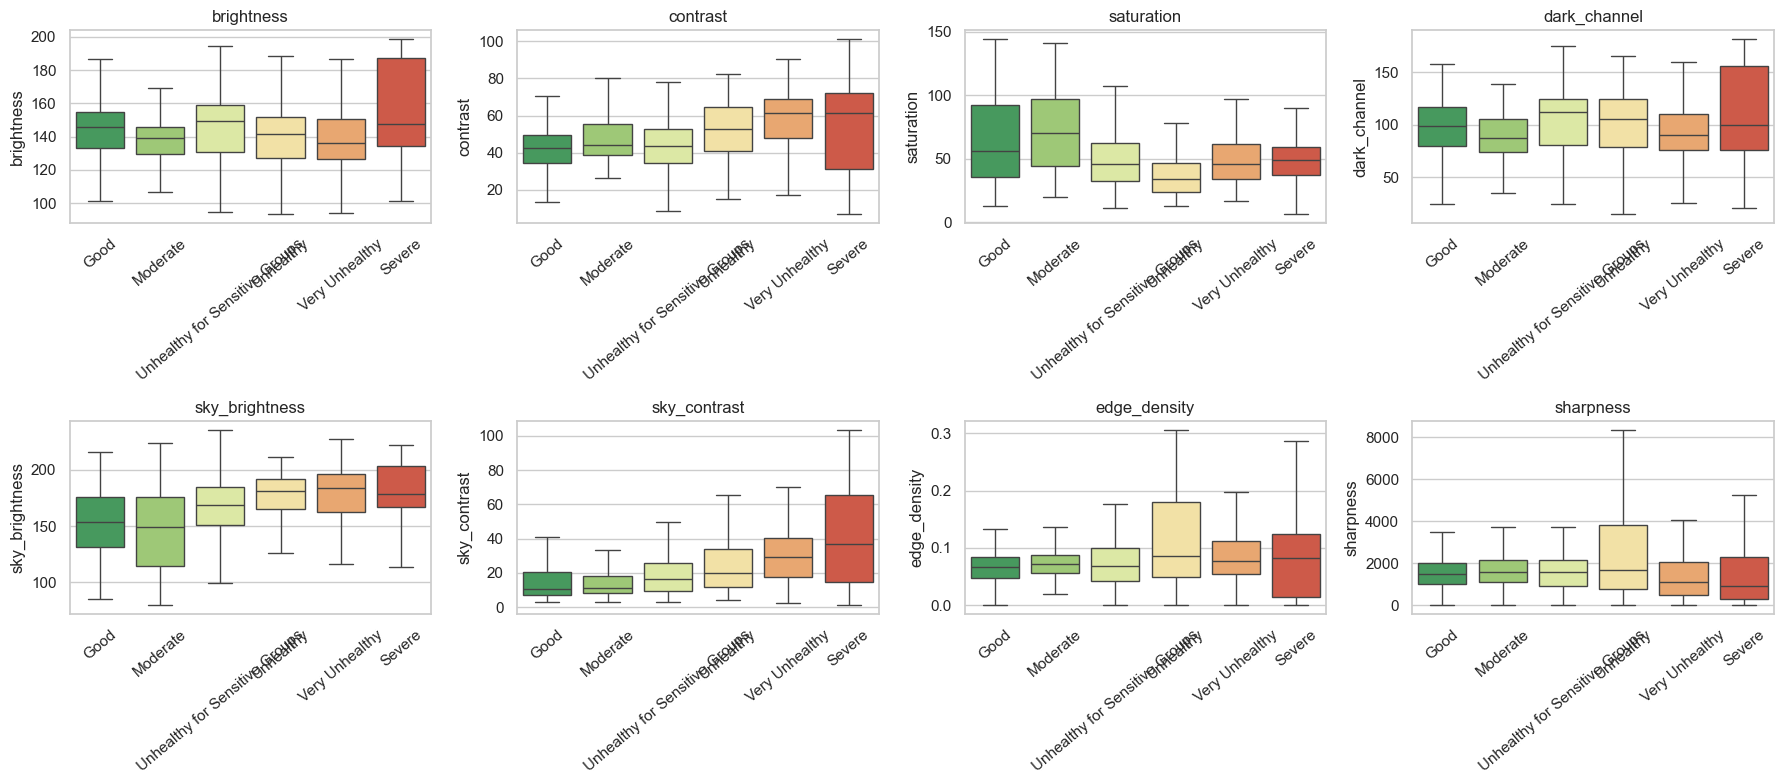

Spearman correlation of each feature with AQI class index:
saturation       -0.194
sharpness        -0.149
edge_density      0.046
brightness        0.052
dark_channel      0.073
contrast          0.291
sky_brightness    0.371
sky_contrast      0.391
dtype: float64


In [12]:
# 4. Handcrafted visual statistics per class (haze cues) — also reused later as a classical baseline
def visual_features(path):
    im = cv2.imread(path)
    if im is None: return None
    im = cv2.resize(im, (IMG_SIZE, IMG_SIZE))
    gray = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
    hsv = cv2.cvtColor(im, cv2.COLOR_BGR2HSV)
    dark = cv2.erode(im.min(axis=2), np.ones((15, 15), np.uint8))
    sky = gray[: IMG_SIZE // 3]
    return dict(brightness=gray.mean(), contrast=gray.std(), saturation=hsv[..., 1].mean(),
                dark_channel=dark.mean(), sky_brightness=sky.mean(), sky_contrast=sky.std(),
                edge_density=(cv2.Canny(gray, 100, 200) > 0).mean(),
                sharpness=cv2.Laplacian(gray, cv2.CV_64F).var())

samp = pd.concat([g.sample(min(len(g), STATS_PER_CLASS), random_state=SEED) for _, g in df.groupby("label")])
rows = []
for _, r in tqdm(samp.iterrows(), total=len(samp)):
    f = visual_features(r.path)
    if f: f.update(label=r.label, label_clean=r.label_clean, path=r.path); rows.append(f)
feat = pd.DataFrame(rows)
feat.to_csv(f"{OUTPUT_DIR}/visual_features.csv", index=False)

fcols = ["brightness", "contrast", "saturation", "dark_channel", "sky_brightness", "sky_contrast", "edge_density", "sharpness"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, f in zip(axes.ravel(), fcols):
    sns.boxplot(data=feat, x="label_clean", y=f, order=class_clean, ax=ax, palette="RdYlGn_r", showfliers=False)
    ax.set_title(f); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=40)
plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/eda_visual_features.png", dpi=130); plt.show()

print("Spearman correlation of each feature with AQI class index:")
print(feat[fcols].corrwith(feat.label, method="spearman").round(3).sort_values())

Metadata columns: ['Location', 'Year', 'Month', 'Day', 'Hour', 'AQI', 'PM2.5', 'PM10', 'O3', 'CO', 'SO2', 'NO2', 'AQI_Class']

Missing fraction:
 Location     0.000
Year         0.000
Month        0.000
Day          0.000
Hour         0.000
AQI          0.000
PM2.5        0.000
PM10         0.000
O3           0.025
CO           0.047
SO2          0.121
NO2          0.036
AQI_Class    0.000


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Location,12240,8,Mumbai,2203,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,12240.0,NaN,NaN,NaN,2022.947631,0.22278,2022.0,2023.0,2023.0,2023.0,2023.0
Month,12240.0,NaN,NaN,NaN,2.686111,1.774345,2.0,2.0,2.0,3.0,10.0
Day,12240.0,NaN,NaN,NaN,12.114706,8.269053,1.0,3.0,13.0,20.0,28.0
Hour,12240,21,8:30,3300,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AQI,12240.0,NaN,NaN,NaN,167.626797,102.818213,15.0,97.0,152.0,230.0,450.0
PM2.5,12240.0,NaN,NaN,NaN,142.999267,130.745815,4.0,35.0,70.08,257.0,500.0
PM10,12240.0,NaN,NaN,NaN,145.663935,104.506951,7.0,64.0,113.0,198.0,480.0
O3,11938.0,NaN,NaN,NaN,39.491436,33.342031,1.0,13.0,31.0,59.66,225.0
CO,11660.0,NaN,NaN,NaN,101.230361,115.910128,0.0,4.0,52.0,174.0,410.0



8 unique groups ('auto'). Top:
 group
Mumbai                           2203
Biratnagar, Nepal                2171
ITO, Delhi                       2168
Bengaluru                        1926
Tamil Nadu                       1540
Knowledge park, Greater Noida    1241
New Ind Town, Faridabad           641
Dimapur, Nagaland                 350
Name: count, dtype: int64


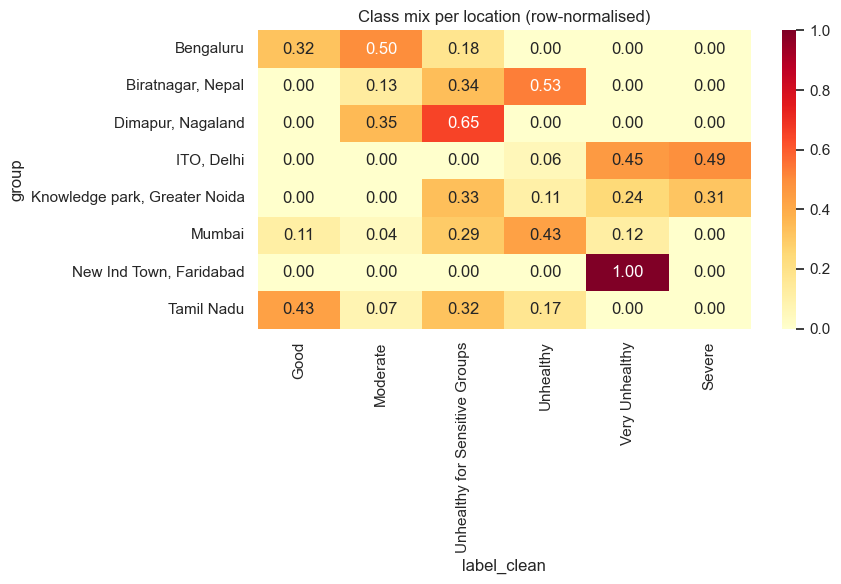

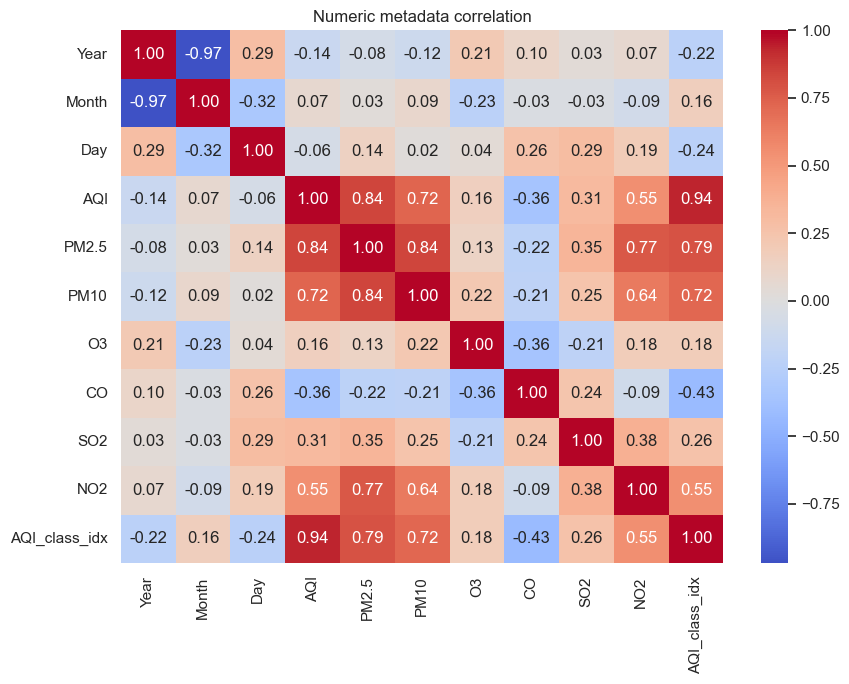

In [13]:
# 5. CSV metadata EDA (locations, pollutants) — runs only if CSV merged
meta_cols = [c for c in df.columns if c not in BASE_COLS]
if not meta_cols:
    print("No CSV metadata merged — skip.")
else:
    print("Metadata columns:", meta_cols)
    print("\nMissing fraction:\n", df[meta_cols].isna().mean().round(3).to_string())
    display(df[meta_cols].describe(include="all").T.head(25))

    if df.group.notna().any():
        top = df.group.value_counts().head(15)
        print(f"\n{df.group.nunique()} unique groups ('{GROUP_COL or 'auto'}'). Top:\n", top)
        mask = df.group.isin(top.index)
        ct = pd.crosstab(df.loc[mask, "group"], df.loc[mask, "label_clean"], normalize="index").reindex(columns=class_clean)
        plt.figure(figsize=(9, 6)); sns.heatmap(ct, annot=True, fmt=".2f", cmap="YlOrRd")
        plt.title("Class mix per location (row-normalised)"); plt.tight_layout()
        plt.savefig(f"{OUTPUT_DIR}/eda_location_vs_class.png", dpi=130); plt.show()

    num = df[meta_cols].select_dtypes("number")
    if num.shape[1] >= 2:
        num = num.assign(AQI_class_idx=df.label)
        plt.figure(figsize=(9, 7)); sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
        plt.title("Numeric metadata correlation"); plt.tight_layout()
        plt.savefig(f"{OUTPUT_DIR}/eda_correlation.png", dpi=130); plt.show()

In [14]:
# 6. Perceptual hashes (aHash) -> near-duplicate / leakage analysis
POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)

def ahash(path):
    g = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if g is None: return None
    g = cv2.resize(g, (8, 8), interpolation=cv2.INTER_AREA)
    return np.packbits((g > g.mean()).flatten()).view(np.uint64)[0]

_h = [ahash(p) for p in tqdm(df.path)]
_ok = np.array([h is not None for h in _h])
if not _ok.all():
    print("Dropping", (~_ok).sum(), "unreadable images")
    df = df[_ok].reset_index(drop=True)
hashes = np.array([h for h in _h if h is not None], dtype=np.uint64)
print("Exact-hash duplicate images:", len(hashes) - len(np.unique(hashes)))

def min_hamming(query, ref, chunk=200):
    out = []
    for i in range(0, len(query), chunk):
        x = query[i:i + chunk, None] ^ ref[None, :]
        d = POP[np.ascontiguousarray(x).view(np.uint8).reshape(*x.shape, 8)].sum(-1)
        out.append(d.min(1))
    return np.concatenate(out)

100%|██████████| 12240/12240 [06:21<00:00, 32.10it/s] 

Exact-hash duplicate images: 4810
